<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 108 · Investigación de Operaciones, aprendizaje por refuerzo y coordinación inteligente</span>

**Sesión 4 · Segunda lección · 55 minutos en clase (ampliaciones para estudio autónomo)**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro,  [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 108 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Qué decisiones conviene aprender de la experiencia y cuáles conviene resolver mediante optimización explícita?

**Fuentes directas:** programa de la sesión 4; cuadernos 103–107 como antecedentes; arquitectura G2.4 y documentación conceptual Hydro-Lab S2.11. **Este cuaderno contiene un problema didáctico reducido, no una integración ejecutada con el simulador real.**

# <span style="color:#174ea6">Contenido y ruta de clase</span>

**55–70 min de la sesión:** robot, grafo de acceso, prioridades, tiempo y batería.  
**70–90 min:** optimización de rutas y asignación; coordinación con prioridades aprendidas.  
**90–100 min:** comparación de cuatro estrategias y valor neto de información.  
**100–110 min:** síntesis: reglas, MPC, RL, BO, meta-learning e Investigación de Operaciones.

**Ruta:** 1. Sistema y decisiones. 2. Formulación de OR. 3. Laboratorio de rutas. 4. Información e inspección. 5. Comparación pareada. 6. Coordinación con RL. 7. Mapa de decisión. 8. Ejercicios y referencias.

# <span style="color:#174ea6">1. El problema: inspeccionar una red de hidrocarburos</span>

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="1050"/>

El robot de inspección visita puntos de una red de transporte de hidrocarburos. Cada desplazamiento consume **tiempo y batería**. Inspeccionar un punto puede revelar una anomalía que justifique modificar el control, detener un equipo o solicitar mantenimiento. El valor de inspeccionar no depende solamente de recorrer una ruta corta: depende también de **qué información se obtiene y cómo cambia la decisión operativa**.

Separaremos dos niveles: (i) **planificación** de una ruta factible mediante optimización combinatoria; (ii) **decisión bajo incertidumbre**, que puede utilizar reglas, modelos probabilísticos o una política aprendida. Esta separación evita atribuir a RL tareas que un algoritmo exacto pequeño resuelve mejor.

## <span style="color:#bd232b">1.1 Estados, acciones y decisiones</span>

En un instante $t$, un estado resumido del planificador es $x_t=(i_t,b_t,T_t,\mathbf p_t,\mathbf h_t)$: posición $i_t$, batería $b_t$, tiempo restante $T_t$, creencias $\mathbf p_t$ sobre anomalías y visitas realizadas $\mathbf h_t$. Las acciones son **visitar un punto**, **inspeccionar** o **regresar a base**. El problema puede modelarse como MDP parcialmente observable si las anomalías no se conocen antes de inspeccionar; aquí construiremos una aproximación explícita y auditable.

# <span style="color:#174ea6">2. Investigación de Operaciones: formulación matemática</span>

Sea $G=(V,E)$ un grafo de acceso, con depósito $0$ y candidatos $I=V\setminus\{0\}$. Para una ruta $R=(0,i_1,\dots,i_k,0)$, definimos $t(R)$ como tiempo de desplazamiento e inspección y $e(R)$ como energía consumida.

Un problema de **orienteering** con restricciones es

$$\max_{R}\ \sum_{i\in I}v_i y_i - c_t t(R)-c_e e(R),$$

sujeto a $t(R)\le T_{\max}$, $e(R)\le B_{\max}$, $y_i\in\{0,1\}$ y a la conectividad de la ruta. $v_i$ es una **estimación previa** del beneficio de inspección, no el estado verdadero oculto del equipo. En una formulación MILP más general se emplean variables binarias $x_{ij}$ para los arcos y restricciones de flujo/subtours.

**Importante:** la ruta más corta y la ruta de mayor valor informativo no son necesariamente la misma.

## <span style="color:#bd232b">2.1 Instancia reproducible: grafo de acceso</span>

El ejemplo reducido tiene cinco nodos, como la arquitectura G2.4, y caminos alternativos. Las longitudes son **sintéticas**; no son distancias ni tiempos de instalaciones reales. La enumeración exacta es apropiada para cuatro objetivos; no escala a redes grandes.

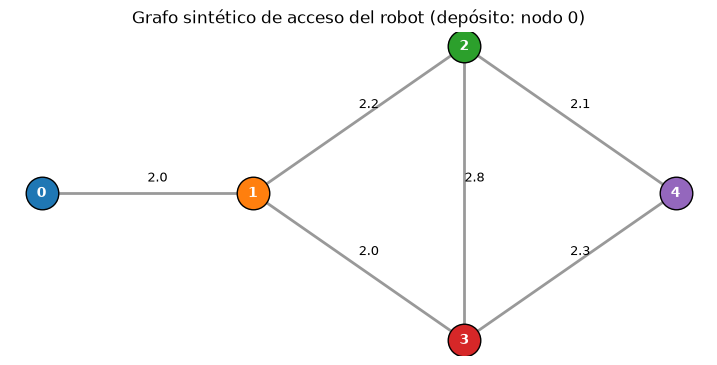

In [1]:
import itertools, heapq, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SEED = 108
rng = np.random.default_rng(SEED)
coords = {0:(0,1), 1:(1,1), 2:(2,2), 3:(2,0), 4:(3,1)}
edges = {(0,1):2.0,(1,2):2.2,(1,3):2.0,(2,4):2.1,(3,4):2.3,(2,3):2.8}
G = {i:[] for i in coords}
for (u,v),w in edges.items():
    G[u].append((v,w)); G[v].append((u,w))

def shortest(source):
    dist={v:float('inf') for v in G};dist[source]=0.;prev={}
    pq=[(0.,source)]
    while pq:
        d,u=heapq.heappop(pq)
        if d>dist[u]:continue
        for v,w in G[u]:
            nd=d+w
            if nd<dist[v]:dist[v]=nd;prev[v]=u;heapq.heappush(pq,(nd,v))
    return dist,prev
DIST={u:shortest(u)[0] for u in G}
assert all(abs(DIST[u][v]-DIST[v][u])<1e-12 for u in G for v in G)
fig,ax=plt.subplots(figsize=(9,4.2))
for (u,v),w in edges.items():
    a,b=coords[u],coords[v]
    ax.plot([a[0],b[0]],[a[1],b[1]],color='0.6',lw=2)
    ax.text((a[0]+b[0])/2,(a[1]+b[1])/2+0.08,str(w),fontsize=9)
for i,(x,y) in coords.items():
    ax.scatter(x,y,s=550,edgecolors='black',zorder=3)
    ax.text(x,y,str(i),ha='center',va='center',color='white',weight='bold',zorder=4)
ax.set_title('Grafo sintético de acceso del robot (depósito: nodo 0)');ax.axis('off');plt.show()

## <span style="color:#bd232b">2.2 Costos y restricciones de la ruta</span>

El tiempo de viaje es proporcional a la longitud mínima de los caminos; cada inspección requiere tiempo adicional. El consumo energético incluye desplazamiento e inspección. Toda ruta debe volver al depósito. **No permitimos planes que agoten la batería antes del regreso.**

In [2]:
TARGETS=(1,2,3,4)
inspection_time={1:0.6,2:0.8,3:0.7,4:0.9}
inspection_energy={1:0.25,2:0.3,3:0.25,4:0.35}
TIME_LIMIT=10.0
BATTERY_LIMIT=8.6
TRAVEL_ENERGY_PER_UNIT=0.72

def route_metrics(stops):
    seq=(0,)+tuple(stops)+(0,)
    distance=sum(DIST[a][b] for a,b in zip(seq[:-1],seq[1:]))
    time=distance+sum(inspection_time[i] for i in stops)
    battery=distance*TRAVEL_ENERGY_PER_UNIT+sum(inspection_energy[i] for i in stops)
    return {'distance':distance,'time':time,'battery':battery,
            'feasible':time<=TIME_LIMIT+1e-10 and battery<=BATTERY_LIMIT+1e-10}

def feasible_routes():
    routes=[()]
    for k in range(1,len(TARGETS)+1):
        routes.extend(r for r in itertools.permutations(TARGETS,k) if route_metrics(r)['feasible'])
    return routes
ROUTES=feasible_routes()
print('Rutas factibles (incluida no inspeccionar):',len(ROUTES))
assert () in ROUTES and all(route_metrics(r)['feasible'] for r in ROUTES)
assert route_metrics((1,2,3,4))['time']>TIME_LIMIT
pd.DataFrame([{'ruta':str(r),**route_metrics(r)} for r in ROUTES]).head(10)

Rutas factibles (incluida no inspeccionar): 8


,ruta,distance,time,battery,feasible
0,(),0.0,0.0,0.000,True
1,"(1,)",4.0,4.6,3.130,True
2,"(2,)",8.4,9.2,6.348,True
3,"(3,)",8.0,8.7,6.010,True
4,"(1, 2)",8.4,9.8,6.598,True
5,"(1, 3)",8.0,9.3,6.260,True
6,"(2, 1)",8.4,9.8,6.598,True
7,"(3, 1)",8.0,9.3,6.260,True


# <span style="color:#174ea6">3. ¿Qué significa el valor de inspeccionar?</span>

Una inspección no produce automáticamente ahorro. Puede revelar un estado oculto que permite elegir una intervención más adecuada. Su **valor esperado de la información** (EVSI) es

$$\operatorname{EVSI}(i)=\mathbb E_{Y_i}\left[\max_a\mathbb E[U(a,H_i)\mid Y_i]\right]-\max_a\mathbb E[U(a,H_i)],$$

con $H_i$ la condición no observada y $Y_i$ el resultado de la inspección. El **valor neto** descuenta el costo de desplazamiento e inspección. No se debe calcular una ruta utilizando los estados verdaderos de anomalía: eso introduciría información privilegiada.

## <span style="color:#bd232b">3.1 Modelo binario de anomalías y sensor imperfecto</span>

Para cada punto $i$, $H_i\in\{0,1\}$ representa ausencia/presencia de anomalía, con probabilidad previa $p_i$. Una intervención preventiva cuesta $C_i$; omitirla cuando existe anomalía genera pérdida $L_i$. La inspección tiene sensibilidad $s$ y especificidad $q$. El agente elige intervenir cuando el costo preventivo es menor que la pérdida esperada posterior.

Este modelo separa **prior**, **medición ruidosa**, **posterior**, **decisión** y **utilidad**, en lugar de confundir prioridad con riesgo realizado.

In [3]:
prior={1:0.16,2:0.38,3:0.29,4:0.48}
loss={1:14.,2:24.,3:18.,4:26.}
prevent_cost={1:5.,2:7.,3:6.,4:8.}
SENSITIVITY=0.85; SPECIFICITY=0.90

def optimal_expected_loss(p,L,C):return min(C,p*L)

def posterior_prob(p,positive):
    py1=p*SENSITIVITY+(1-p)*(1-SPECIFICITY)
    if positive:return p*SENSITIVITY/py1
    return p*(1-SENSITIVITY)/(1-py1)

def evsi(p,L,C):
    py1=p*SENSITIVITY+(1-p)*(1-SPECIFICITY)
    after=py1*optimal_expected_loss(posterior_prob(p,True),L,C)
    after+=(1-py1)*optimal_expected_loss(posterior_prob(p,False),L,C)
    return optimal_expected_loss(p,L,C)-after

VALUES={i:evsi(prior[i],loss[i],prevent_cost[i]) for i in TARGETS}
print(pd.DataFrame([{'nodo':i,'prob_anomalia':prior[i],'EVSI':VALUES[i]} for i in TARGETS]).round(3).to_string(index=False))
assert all(v>=-1e-10 for v in VALUES.values())
assert abs(posterior_prob(0.3,True)-0.3*0.85/(0.3*0.85+0.7*0.1))<1e-12

 nodo  prob_anomalia  EVSI
    1           0.16 0.804
    2           0.38 2.937
    3           0.29 2.532
    4           0.48 2.448


## <span style="color:#bd232b">3.2 Planificación óptima por enumeración exacta</span>

Maximizamos el beneficio esperado de información menos costos operativos de la ruta. Con solo cuatro nodos de inspección, enumerar todas las rutas factibles ofrece un óptimo verificable. Para redes grandes se requerirían MILP, programación dinámica, búsqueda local o heurísticas con control de factibilidad.

In [4]:
COST_TIME=0.10; COST_BATTERY=0.08

def route_value(route,values=VALUES):
    m=route_metrics(route)
    return sum(values[i] for i in route)-COST_TIME*m['time']-COST_BATTERY*m['battery']

def optimize_route(values=VALUES):
    return max(ROUTES,key=lambda r:(route_value(r,values),-route_metrics(r)['time']))
BEST=optimize_route()
print('Ruta OR óptima:',(0,)+BEST+(0,))
print('Métricas:',route_metrics(BEST),'valor neto esperado:',round(route_value(BEST),3))
assert route_metrics(BEST)['feasible']
assert route_value(BEST)>=max(route_value(r) for r in ROUTES)-1e-12

Ruta OR óptima: (0, 1, 2, 0)
Métricas: {'distance': 8.4, 'time': 9.8, 'battery': 6.598, 'feasible': True} valor neto esperado: 2.233


## <span style="color:#bd232b">3.3 Visualización de la ruta factible</span>

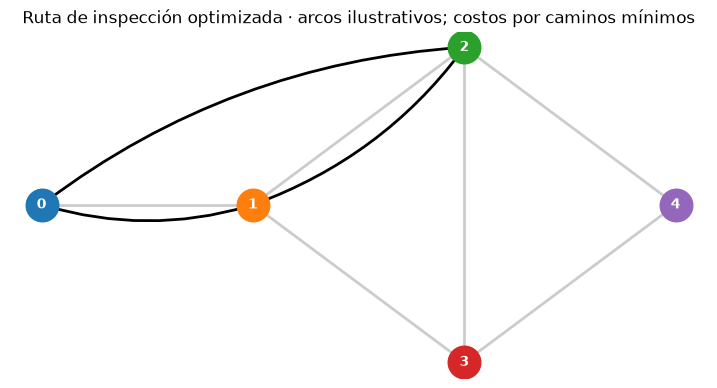

In [5]:
def draw_route(stops,title):
    fig,ax=plt.subplots(figsize=(9,4.5))
    for (u,v),w in edges.items():
        a,b=coords[u],coords[v];ax.plot([a[0],b[0]],[a[1],b[1]],color='0.8',lw=2)
    for a,b in zip((0,)+tuple(stops),tuple(stops)+(0,)):
        # Ruta lógica sobre distancias mínimas; segmentos rectos son ilustrativos.
        x,y=coords[a],coords[b]
        ax.annotate('',xy=y,xytext=x,arrowprops=dict(arrowstyle='->',lw=2,connectionstyle='arc3,rad=0.15'))
    for i,(x,y) in coords.items():
        ax.scatter(x,y,s=550,zorder=3);ax.text(x,y,str(i),ha='center',va='center',color='white',weight='bold',zorder=4)
    ax.set_title(title+' · arcos ilustrativos; costos por caminos mínimos');ax.axis('off');plt.show()
draw_route(BEST,'Ruta de inspección optimizada')

# <span style="color:#174ea6">4. Comparación de estrategias con escenarios pareados</span>

Comparamos cuatro políticas bajo **los mismos estados ocultos y resultados potenciales del sensor por semilla**:

1. **No inspeccionar:** actuar solo con información previa.
2. **Calendario fijo:** visitar nodos según orden predefinido, respetando presupuesto.
3. **Ruta OR:** optimizar usando valores esperados de información.
4. **Coordinación informada:** actualizar las probabilidades previas con una señal contextual observable y volver a optimizar.

La señal contextual es ruidosa, se observa **antes** de decidir y no revela el estado verdadero. La evaluación usa la pérdida realizada por intervención/omisión y el costo de ruta; no reutiliza el EVSI como si fuera recompensa observada.

## <span style="color:#bd232b">4.1 Políticas y simulación de episodios</span>

In [6]:
CALENDAR=(1,3)
assert route_metrics(CALENDAR)['feasible']

def bayes_from_signal(p,signal,tpr=0.70,fpr=0.30):
    num=p*(tpr if signal else 1-tpr)
    den=num+(1-p)*(fpr if signal else 1-fpr)
    return num/den

def choose_route(strategy,signals):
    if strategy=='Sin inspección':return (),dict(prior)
    if strategy=='Calendario':return CALENDAR,dict(prior)
    if strategy=='OR':return BEST,dict(prior)
    if strategy=='Coordinación':
        p={i:bayes_from_signal(prior[i],signals[i]) for i in TARGETS}
        v={i:evsi(p[i],loss[i],prevent_cost[i]) for i in TARGETS}
        return optimize_route(v),p
    raise ValueError(strategy)

def realized_loss(truth,intervene,L,C):return C if intervene else (L if truth else 0.)

def evaluate_policy(strategy,scenario):
    route,p=choose_route(strategy,scenario['signals'])
    total=0.
    for i in TARGETS:
        post=posterior_prob(p[i],scenario['inspection'][i]) if i in route else p[i]
        intervene=prevent_cost[i]<post*loss[i]
        total+=realized_loss(scenario['truth'][i],intervene,loss[i],prevent_cost[i])
    m=route_metrics(route)
    total+=COST_TIME*m['time']+COST_BATTERY*m['battery']
    return {'strategy':strategy,'loss':total,'route':str((0,)+route+(0,)),
            'time':m['time'],'battery':m['battery'],'feasible':m['feasible']}

def generate_scenario(seed):
    r=np.random.default_rng(seed)
    truth={i:bool(r.random()<prior[i]) for i in TARGETS}
    signals={i:bool(r.random()<(0.70 if truth[i] else 0.30)) for i in TARGETS}
    inspection={i:bool(r.random()<(SENSITIVITY if truth[i] else 1-SPECIFICITY)) for i in TARGETS}
    return {'truth':truth,'signals':signals,'inspection':inspection}

STRATEGIES=['Sin inspección','Calendario','OR','Coordinación']
scenario=generate_scenario(108)
pd.DataFrame([evaluate_policy(s,scenario) for s in STRATEGIES])

,strategy,loss,route,time,battery,feasible
0,Sin inspección,33.00000,"(0, 0)",0.0,0.000,True
1,Calendario,22.43080,"(0, 1, 3, 0)",9.3,6.260,True
2,OR,27.50784,"(0, 1, 2, 0)",9.8,6.598,True
3,Coordinación,40.43080,"(0, 1, 3, 0)",9.3,6.260,True


## <span style="color:#bd232b">4.2 Evaluación pareada y bandas de incertidumbre</span>

Se fijan las mismas 500 semillas de evaluación para las cuatro estrategias. Esta comparación **reduce variación Monte Carlo**, pero no sustituye una validación en el simulador hidráulico. La incertidumbre se resume mediante intervalos de confianza del promedio de la diferencia pareada.

                mean_loss  sd_loss  mean_time  mean_battery
strategy                                                   
Calendario         20.397    4.996      9.300         6.260
Coordinación       18.686   11.755      7.799         5.250
OR                 20.496   10.729      9.800         6.598
Sin inspección     22.380    9.783      0.000         0.000
Beneficio pareado vs no inspeccionar, Calendario: 1.983, IC95% aprox [1.399, 2.567]
Beneficio pareado vs no inspeccionar, OR: 1.884, IC95% aprox [1.226, 2.542]
Beneficio pareado vs no inspeccionar, Coordinación: 3.694, IC95% aprox [2.710, 4.678]


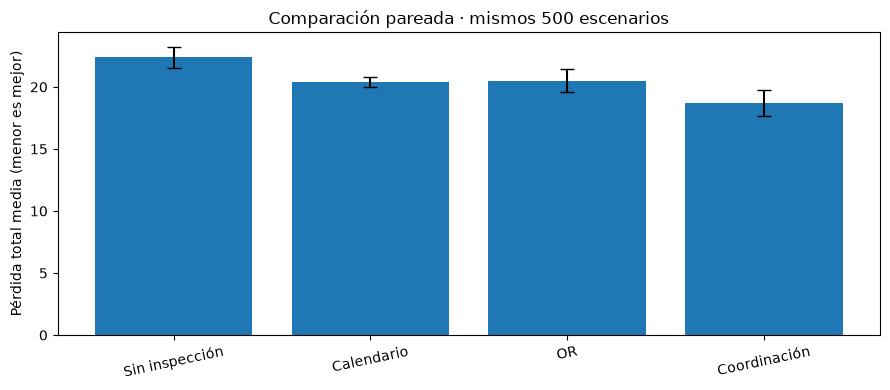

In [7]:
N_TEST=500
records=[]
for seed in range(5000,5000+N_TEST):
    sc=generate_scenario(seed)
    for strategy in STRATEGIES:
        records.append({'seed':seed,**evaluate_policy(strategy,sc)})
results=pd.DataFrame(records)
assert results.feasible.all()
summary=results.groupby('strategy').agg(mean_loss=('loss','mean'),sd_loss=('loss','std'),
                                         mean_time=('time','mean'),mean_battery=('battery','mean'))
print(summary.round(3))
pivot=results.pivot(index='seed',columns='strategy',values='loss')
base=pivot['Sin inspección']
for s in STRATEGIES[1:]:
    delta=(base-pivot[s]).to_numpy()
    se=delta.std(ddof=1)/np.sqrt(len(delta))
    print(f'Beneficio pareado vs no inspeccionar, {s}: {delta.mean():.3f}, IC95% aprox [{delta.mean()-1.96*se:.3f}, {delta.mean()+1.96*se:.3f}]')
fig,ax=plt.subplots(figsize=(9,4))
means=summary.loc[STRATEGIES,'mean_loss'];errs=1.96*summary.loc[STRATEGIES,'sd_loss']/np.sqrt(N_TEST)
ax.bar(STRATEGIES,means,yerr=errs,capsize=5)
ax.set_ylabel('Pérdida total media (menor es mejor)');ax.set_title('Comparación pareada · mismos 500 escenarios')
plt.xticks(rotation=12);plt.tight_layout();plt.show()

## <span style="color:#bd232b">4.3 Sensibilidad y límites del experimento</span>

El desempeño depende de la calidad de las probabilidades previas, la sensibilidad/especificidad del sensor, el costo de las intervenciones y el presupuesto de la ruta. **La coordinación informada puede perder** cuando su señal es poco fiable o cuando el valor adicional de información no compensa el desplazamiento. Nunca debemos asumir que RL o coordinación superan a OR sin evidencia.

En el laboratorio, la coordinación utiliza un **modelo probabilístico explícito** como sustituto de un predictor aprendido. No afirmamos que se haya entrenado una política RL para inspección.

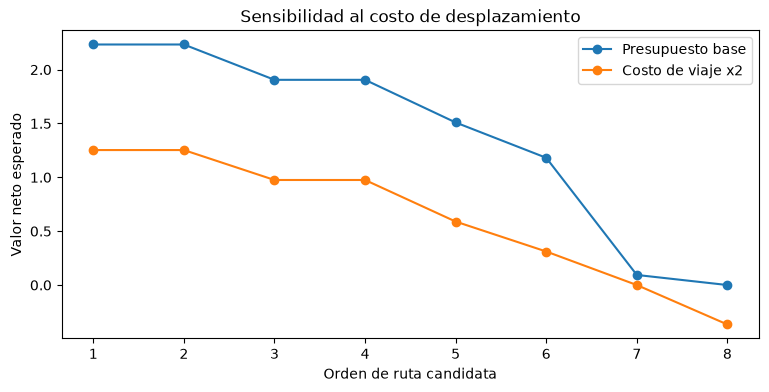

In [8]:
fig,ax=plt.subplots(figsize=(9,4))
for label,alpha in [('Presupuesto base',1.0),('Costo de viaje x2',2.0)]:
    vals=[]
    for r in ROUTES:
        m=route_metrics(r)
        vals.append(sum(VALUES[i] for i in r)-alpha*COST_TIME*m['time']-COST_BATTERY*m['battery'])
    vals=np.sort(vals)[::-1]
    ax.plot(range(1,min(16,len(vals))+1),vals[:16],marker='o',label=label)
ax.set_xlabel('Orden de ruta candidata');ax.set_ylabel('Valor neto esperado');ax.set_title('Sensibilidad al costo de desplazamiento');ax.legend();plt.show()

# <span style="color:#174ea6">5. ¿Cómo se integraría RL con Investigación de Operaciones?</span>

**Arquitectura jerárquica propuesta:** una política aprendida recibe observaciones operativas y propone **prioridades o recompensas de inspección**; el planificador OR convierte esas prioridades en una ruta **factible** bajo restricciones de batería, tiempo y acceso. El planificador puede rechazar propuestas incompatibles con la seguridad.

$$\text{Observaciones}\ \longrightarrow\ \underbrace{\pi_\theta}_{\text{prioridades aprendidas}}\ \longrightarrow\ \underbrace{\arg\max_{R\in\mathcal F}\sum_{i\in R}\widehat v_i-c(R)}_{\text{planificador OR}}\ \longrightarrow\ \text{ruta ejecutable}.$$

Una segunda opción es usar OR como **experto** para generar demostraciones o como capa de seguridad en un agente RL. En ambos casos es imprescindible definir el momento en que la información se vuelve observable; no puede introducirse la verdad de la simulación en las entradas de la política.

## <span style="color:#bd232b">5.1 Ejercicio ejecutable: prioridades propuestas y proyección factible</span>

In [9]:
def project_priorities_to_feasible_route(priorities):
    assert set(priorities)==set(TARGETS)
    return optimize_route(priorities)
proposed={1:0.5,2:2.0,3:1.2,4:3.0} # salida ilustrativa, NO entrenada
projected=project_priorities_to_feasible_route(proposed)
print('Prioridades ilustrativas:',proposed)
print('Ruta OR factible:',(0,)+projected+(0,),route_metrics(projected))
assert route_metrics(projected)['feasible']

Prioridades ilustrativas: {1: 0.5, 2: 2.0, 3: 1.2, 4: 3.0}
Ruta OR factible: (0, 1, 2, 0) {'distance': 8.4, 'time': 9.8, 'battery': 6.598, 'feasible': True}


# <span style="color:#174ea6">6. Síntesis ejecutiva: ¿qué técnica corresponde a cada problema?</span>

| Técnica | Qué resuelve mejor | Límite importante |
|---|---|---|
| Reglas | Respuestas auditables y restricciones simples | Fragilidad ante situaciones no previstas |
| MPC | Control dinámico con modelo y restricciones | Costo de modelado y optimización en línea |
| RL/PPO | Políticas secuenciales bajo incertidumbre y simulación | Necesita entrenamiento y validación cuidadosos |
| Optimización bayesiana | Elegir evaluaciones costosas con presupuesto limitado | No sustituye al control en tiempo real |
| Meta-learning | Adaptación rápida entre tareas relacionadas | La ganancia frente a baselines debe demostrarse |
| OR | Rutas, asignación y factibilidad combinatoria | Requiere prioridades y costos bien especificados |

**Decisión final:** combinar aprendizaje y optimización explícita cuando cada uno aporta una capacidad verificable; no combinar algoritmos por moda.

# <span style="color:#174ea6">7. Conexión responsable con Hydro-Lab S2.11</span>

En Hydro-Lab la política PPO documentada controla tres acciones continuas normalizadas asociadas a bombas. La planificación del robot en este cuaderno es un **subproblema didáctico adicional**. Para una integración futura, haría falta verificar en el código del simulador qué observaciones del robot existen, cuáles son sus acciones disponibles y cómo afecta una inspección a la operación.

**Protocolo de integración, no resultado ejecutado:** (1) definir grafo y restricciones reales del escenario sintético; (2) extraer creencias sin usar `evaluation_truth`; (3) calcular prioridades; (4) resolver ruta factible; (5) ejecutar y registrar observaciones; (6) comparar estrategias en semillas pareadas y tareas no vistas; (7) reportar servicio, energía, desgaste, seguridad y costo de inspección. **No se modifica la aplicación para completar esta lección.**

# <span style="color:#174ea6">8. Actividades y preguntas de contraste</span>

1. Cambia el presupuesto de batería y explica qué rutas dejan de ser factibles. ¿El mejor valor neto siempre aumenta al ampliar el presupuesto?
2. Reduce la especificidad del sensor a 0.60. ¿Cómo cambia el EVSI? Explica por qué la información imperfecta puede valer menos.
3. Duplica el costo de inspección en el nodo 4 y recalcula la ruta óptima.
4. Compara **OR** y **coordinación informada** en los mismos escenarios. ¿Hay evidencia de una diferencia media distinta de cero?
5. Diseña una interfaz entre una política PPO que asigna prioridades y un planificador OR que impone restricciones. ¿Qué variables pueden observarse antes de actuar?
6. **Pregunta central:** ¿qué partes deben aprenderse y cuáles deben resolverse mediante optimización explícita?

**Entrega breve:** ruta, prueba de factibilidad, tabla de comparación pareada, incertidumbre de las diferencias y recomendación ejecutiva sustentada.

# <span style="color:#174ea6">9. Fuentes, atribución y licencia</span>

**Materiales de partida:** programa de las sesiones 3 y 4 del curso; cuadernos 103–107 de Aprendizaje Profundo; imagen institucional `../Imagenes/logo-final-ap.png`; arquitectura `../Imagenes/arquitectura_laboratorio_G2.4.png`. El problema de rutas, parámetros y datos del laboratorio son sintéticos.

**Bibliografía de referencia:**

- Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed.
- Bertsimas, D. y Tsitsiklis, J. N. (1997). *Introduction to Linear Optimization*.
- Toth, P. y Vigo, D. (eds.) (2014). *Vehicle Routing: Problems, Methods, and Applications*, 2.ª ed.
- Powell, W. B. (2022). *Reinforcement Learning and Stochastic Optimization*.
- Howard, R. A. (1966). *Information Value Theory*. IEEE Transactions on Systems Science and Cybernetics.

**Licencia:** MIT para el texto y código originales de esta edición; las imágenes preexistentes y materiales de terceros conservan sus derechos y condiciones aplicables. MIT no implica licencia sobre marcas institucionales, el logotipo ni software de terceros.